# **Практическая работа. Геомаркетинговое исследование территорий с применением методов машинного обучения**


## **Цель работы**


Овладеть методами пространственного анализа и машинного обучения для решения практической задачи определения оптимальных локаций размещения коммерческих объектов.

## **Введение**


В современном бизнесе местоположение коммерческого объекта играет ключевую роль в его успешности. Геомаркетинговый анализ позволяет объективно оценить привлекательность различных локаций, опираясь на количественные показатели и алгоритмы машинного обучения.

В рамках данной работы вы примените полный цикл пространственного анализа, включая сбор данных из открытых источников, обработку и агрегацию пространственной информации, обучение моделей машинного обучения и визуализацию результатов.

## **Задание**


Провести геомаркетинговое исследование для выбора оптимальных локаций размещения новых точек определенного типа бизнеса на территории выбранного города.

## **Порядок выполнения работы**

### **Часть 1. Подготовка данных и определение задачи**



1. **Индивидуальный выбор территории и типа бизнеса**:
   - Выберите город/район для проведения анализа (например, центральная часть Москвы, Санкт-Петербурга или любого другого крупного города)
   - Определите тип бизнеса для анализа (аптеки, продуктовые магазины, пункты выдачи заказов, рестораны определенной кухни и т.д.)
   - Обоснуйте свой выбор: почему данная территория и тип бизнеса интересны для анализа?

2. **Определение ключевых факторов успешности**:
   - Самостоятельно сформулируйте не менее 5 факторов, которые могут влиять на успешность выбранного типа бизнеса
   - Для каждого фактора определите, какими данными из OpenStreetMap его можно количественно описать
   - Составьте таблицу соответствия между факторами и тегами OpenStreetMap

3. **Сбор исходных данных**:
   - Настройте необходимые библиотеки из теоретического материала
   - Определите необходимую область интереса (ROI) с помощью интерактивной карты
   - Загрузите данные о существующих объектах вашего типа бизнеса и объектах инфраструктуры, связанных с выделенными вами факторами

In [3]:
import time
import osmnx as ox

ox.settings.use_cache = True
ox.settings.requests_timeout = 180

def load_osm(place, tags, attempts=4):
    for i in range(attempts):
        try:
            return ox.features_from_place(place, tags=tags)
        except Exception as e:
            print(f"Попытка {i + 1} не удалась:", e)

            if i < attempts - 1:
                print("Ждем 15 секунд и пробуем снова...")
                time.sleep(15)

    raise Exception("Не удалось получить данные OpenStreetMap")

cafes = load_osm(
    place,
    {"amenity": "cafe"}
)

shops = load_osm(
    place,
    {"shop": True}
)

transport = load_osm(
    place,
    {
        "public_transport": True,
        "railway": ["station", "subway_entrance", "tram_stop"]
    }
)

education = load_osm(
    place,
    {"amenity": ["school", "college", "university"]}
)

tourism = load_osm(
    place,
    {"tourism": True}
)

parks = load_osm(
    place,
    {"leisure": "park"}
)

offices = load_osm(
    place,
    {"office": True}
)

restaurants = load_osm(
    place,
    {"amenity": ["restaurant", "fast_food"]}
)

pedestrian = load_osm(
    place,
    {"highway": "pedestrian"}
)

print("Кофейни:", len(cafes))
print("Магазины:", len(shops))
print("Транспорт:", len(transport))
print("Образование:", len(education))
print("Туризм:", len(tourism))
print("Парки:", len(parks))
print("Офисы:", len(offices))
print("Рестораны:", len(restaurants))
print("Пешеходные объекты:", len(pedestrian))

Кофейни: 821
Магазины: 4328
Транспорт: 602
Образование: 130
Туризм: 1140
Парки: 129
Офисы: 1303
Рестораны: 797
Пешеходные объекты: 31


### **Часть 2. Пространственное агрегирование и создание признаков**


1. **Создание гексагональной сетки**:
   - Самостоятельно определите оптимальную детализацию сетки H3 для вашего анализа
   - Обоснуйте выбор разрешения (resolution) сетки с учётом масштаба вашей территории и специфики бизнеса
   - Покройте территорию гексагональной сеткой выбранного разрешения

2. **Инженерия пространственных признаков**:
   - Определите радиусы для анализа ближнего и среднего окружения (могут отличаться от предложенных в теории в зависимости от специфики вашего бизнеса)
   - Разработайте и реализуйте не менее 10 пространственных признаков, описывающих характеристики каждой ячейки
   - **Дополнительное задание**: придумайте и реализуйте не менее 2 пространственных признаков, которых нет в теоретическом материале

3. **Анализ полученных признаков**:
   - Рассчитайте базовую статистику по каждому признаку
   - Исследуйте корреляции между признаками
   - Выявите и обработайте выбросы и пропущенные значения, если они имеются

Количество H3-ячеек: 200


C:\Users\jopna\AppData\Local\Temp\ipykernel_41652\2319143225.py:84: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  union = pts.geometry.unary_union
C:\Users\jopna\AppData\Local\Temp\ipykernel_41652\2319143225.py:84: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  union = pts.geometry.unary_union


,count,mean,std,min,25%,50%,75%,max
cafes,200.0,4.035000,4.787313,0.000000,0.000000,2.000000,6.000000,24.000000
shops,200.0,21.480000,28.027976,0.000000,2.000000,9.500000,34.250000,167.000000
transport,200.0,2.950000,4.130716,0.000000,0.000000,2.000000,4.000000,25.000000
education,200.0,0.635000,0.941385,0.000000,0.000000,0.000000,1.000000,5.000000
tourism,200.0,5.645000,10.588178,0.000000,0.000000,2.000000,8.000000,120.000000
parks,200.0,0.640000,0.913550,0.000000,0.000000,0.000000,1.000000,5.000000
offices,200.0,6.400000,7.085267,0.000000,1.000000,4.000000,10.000000,38.000000
restaurants,200.0,3.955000,5.283232,0.000000,0.000000,2.000000,5.000000,34.000000
pedestrian,200.0,0.155000,0.709572,0.000000,0.000000,0.000000,0.000000,6.000000
dist_transport,200.0,198.920066,159.225871,16.687945,98.014659,149.223596,253.070458,946.919303


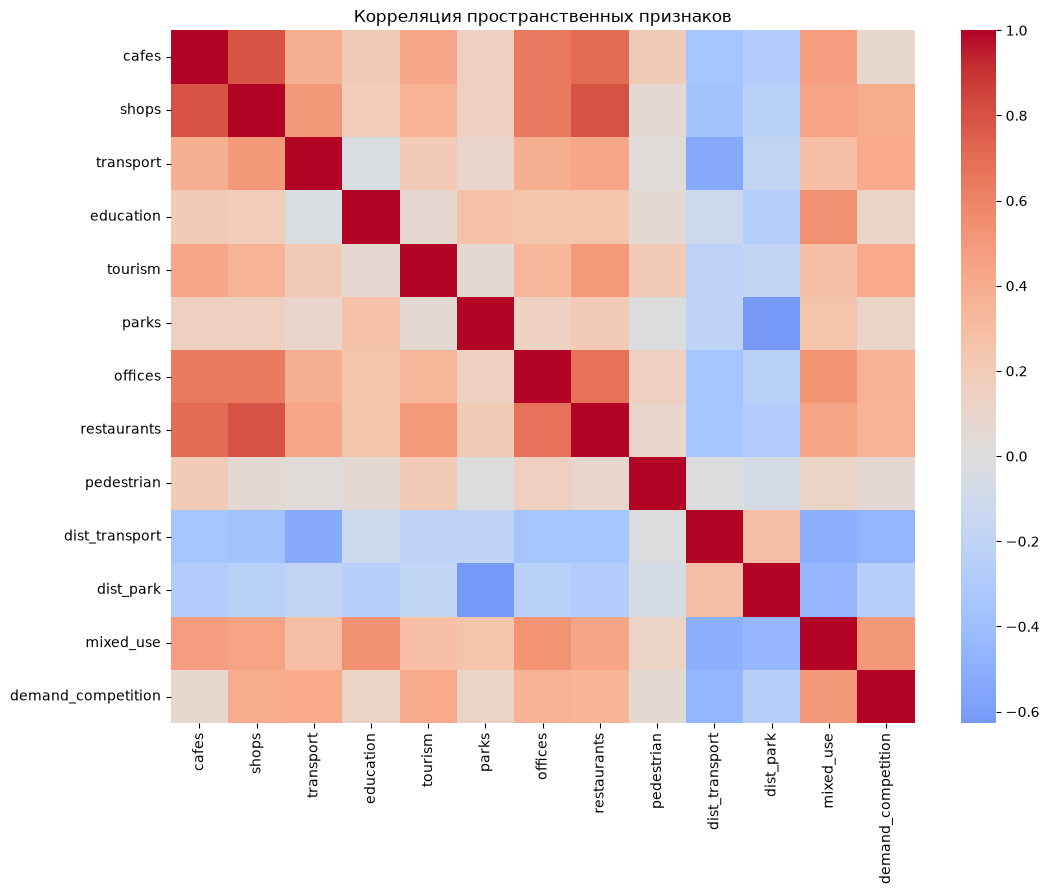

In [4]:
# H3 resolution 9: ячейки порядка нескольких сотен метров.
# Для кофейни это удобный масштаб локального пешеходного окружения.
resolution = 9

# Формируем H3-ячейки, покрывающие ROI
geom = roi.geometry.iloc[0]
geojson = geom.__geo_interface__

cells = list(h3.geo_to_cells(geojson, resolution))

def cell_polygon(cell):
    coords = h3.cell_to_boundary(cell)
    return Polygon([(lng, lat) for lat, lng in coords])

grid = gpd.GeoDataFrame(
    {"h3": cells},
    geometry=[cell_polygon(c) for c in cells],
    crs="EPSG:4326"
)

# Оставляем только ячейки, пересекающиеся с районом
grid = gpd.sjoin(
    grid,
    roi[["geometry"]],
    predicate="intersects"
).drop(columns="index_right")

grid = grid.drop_duplicates("h3").reset_index(drop=True)

# Центроиды в метрической системе координат
grid_m = grid.to_crs("EPSG:32636")
grid["centroid"] = grid_m.centroid.to_crs("EPSG:4326")
grid["lon"] = grid["centroid"].x
grid["lat"] = grid["centroid"].y

print("Количество H3-ячеек:", len(grid))

# Приводим любые геометрии к точкам для подсчетов/расстояний
def prepare_points(gdf):
    a = gdf.copy()
    a = a[a.geometry.notna()].to_crs("EPSG:4326")
    a["geometry"] = a.geometry.representative_point()
    return a

cafes_p = prepare_points(cafes)
shops_p = prepare_points(shops)
transport_p = prepare_points(transport)
education_p = prepare_points(education)
tourism_p = prepare_points(tourism)
parks_p = prepare_points(parks)
offices_p = prepare_points(offices)
restaurants_p = prepare_points(restaurants)
pedestrian_p = prepare_points(pedestrian)

# Число объектов каждого типа в каждой H3-ячейке
def add_count(grid_df, points, name):
    pts = points.copy()
    pts["h3"] = [
        h3.latlng_to_cell(p.y, p.x, resolution)
        for p in pts.geometry
    ]

    counts = pts.groupby("h3").size()
    grid_df[name] = grid_df["h3"].map(counts).fillna(0).astype(int)

add_count(grid, cafes_p, "cafes")
add_count(grid, shops_p, "shops")
add_count(grid, transport_p, "transport")
add_count(grid, education_p, "education")
add_count(grid, tourism_p, "tourism")
add_count(grid, parks_p, "parks")
add_count(grid, offices_p, "offices")
add_count(grid, restaurants_p, "restaurants")
add_count(grid, pedestrian_p, "pedestrian")

# Расстояния до ближайшего объекта в метрах
def nearest_distance(centers_gdf, points_gdf):
    centers = centers_gdf.to_crs("EPSG:32636")
    pts = points_gdf.to_crs("EPSG:32636")

    if len(pts) == 0:
        return np.full(len(centers), np.nan)

    union = pts.geometry.unary_union
    return centers.geometry.apply(lambda x: x.distance(union)).values

grid["dist_transport"] = nearest_distance(
    gpd.GeoDataFrame(grid, geometry="centroid", crs="EPSG:4326"),
    transport_p
)

grid["dist_park"] = nearest_distance(
    gpd.GeoDataFrame(grid, geometry="centroid", crs="EPSG:4326"),
    parks_p
)

# Дополнительные признаки, которых нет в базовом списке:
# 1) индекс смешанности функций
grid["mixed_use"] = (
    (grid["shops"] > 0).astype(int) +
    (grid["offices"] > 0).astype(int) +
    (grid["education"] > 0).astype(int) +
    (grid["tourism"] > 0).astype(int)
)

# 2) отношение "спрос / конкуренция"
grid["demand_competition"] = (
    grid["shops"] +
    grid["offices"] +
    grid["tourism"] +
    grid["transport"]
) / (1 + grid["cafes"])

feature_cols = [
    "cafes",
    "shops",
    "transport",
    "education",
    "tourism",
    "parks",
    "offices",
    "restaurants",
    "pedestrian",
    "dist_transport",
    "dist_park",
    "mixed_use",
    "demand_competition"
]

# Пропуски расстояний заполняем медианой
for col in ["dist_transport", "dist_park"]:
    grid[col] = grid[col].fillna(grid[col].median())

display(grid[feature_cols].describe().T)

# Корреляции
plt.figure(figsize=(12, 9))
sns.heatmap(
    grid[feature_cols].corr(),
    cmap="coolwarm",
    center=0
)
plt.title("Корреляция пространственных признаков")
plt.show()

# Обработка выбросов: ограничиваем значения 99-м перцентилем
for col in feature_cols:
    q = grid[col].quantile(0.99)
    grid[col] = grid[col].clip(upper=q)

### **Часть 3. Моделирование привлекательности локаций**



1. **Подготовка целевой переменной**:
   - Определите, как будет сформирована целевая переменная для вашей задачи (по умолчанию: наличие объектов выбранного типа в ячейке)
   - Исследуйте распределение целевой переменной и оцените её сбалансированность
   - При необходимости, предложите стратегию работы с несбалансированными данными

2. **Разработка моделей машинного обучения**:
   - Реализуйте и обучите несколько моделей (минимум 2) для предсказания привлекательности локации
   - Проведите оценку важности признаков для каждой модели
   - Сравните модели по метрикам качества и выберите наилучшую
   - **Дополнительное задание**: настройте гиперпараметры модели с помощью поиска по сетке (GridSearchCV) или случайного поиска (RandomSearchCV)

3. **Улучшение модели с помощью кластеризации**:
   - Выполните кластеризацию ячеек по их характеристикам
   - Определите оптимальное число кластеров с помощью метода локтя или силуэта
   - Визуализируйте результаты кластеризации
   - Проверьте, улучшает ли добавление информации о кластерах качество основной модели

Распределение целевой переменной:
target
1    138
0     62
Name: count, dtype: int64
target
1    0.69
0    0.31
Name: proportion, dtype: float64


,model,accuracy,precision,recall,f1,roc_auc
0,Logistic Regression,0.94,1.000000,0.914286,0.955224,1.000000
1,Random Forest,0.92,0.942857,0.942857,0.942857,0.971429


,feature,importance
0,shops,0.241466
10,mixed_use,0.153085
5,offices,0.152968
11,demand_competition,0.132041
6,restaurants,0.098894
3,tourism,0.066906
8,dist_transport,0.053907
9,dist_park,0.043404
1,transport,0.032024
4,parks,0.012703


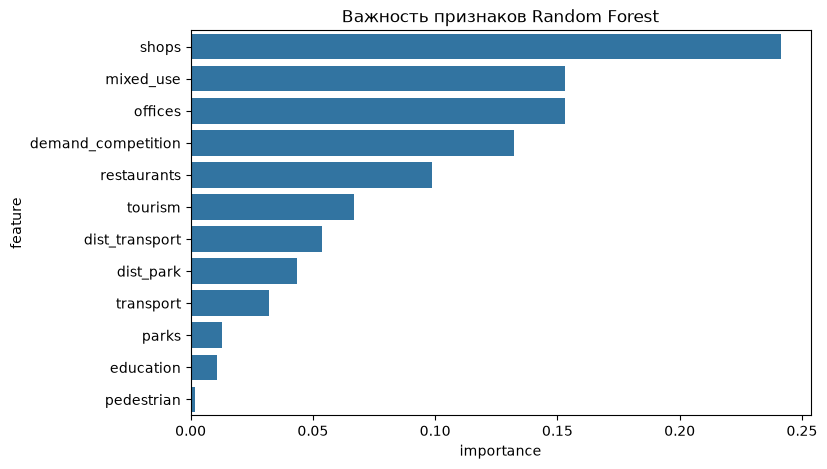

Лучшие параметры Random Forest:
{'max_depth': 10, 'min_samples_leaf': 3, 'n_estimators': 100}


C:\Users\jopna\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\jopna\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\jopna\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\jopna\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window

,k,silhouette
0,2,0.233212
1,3,0.196248
2,4,0.211317
3,5,0.173625
4,6,0.171756
5,7,0.180357
6,8,0.171637


C:\Users\jopna\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


Лучшее число кластеров: 2
Random Forest + cluster
F1: 0.9411764705882353
ROC-AUC: 0.9904761904761905


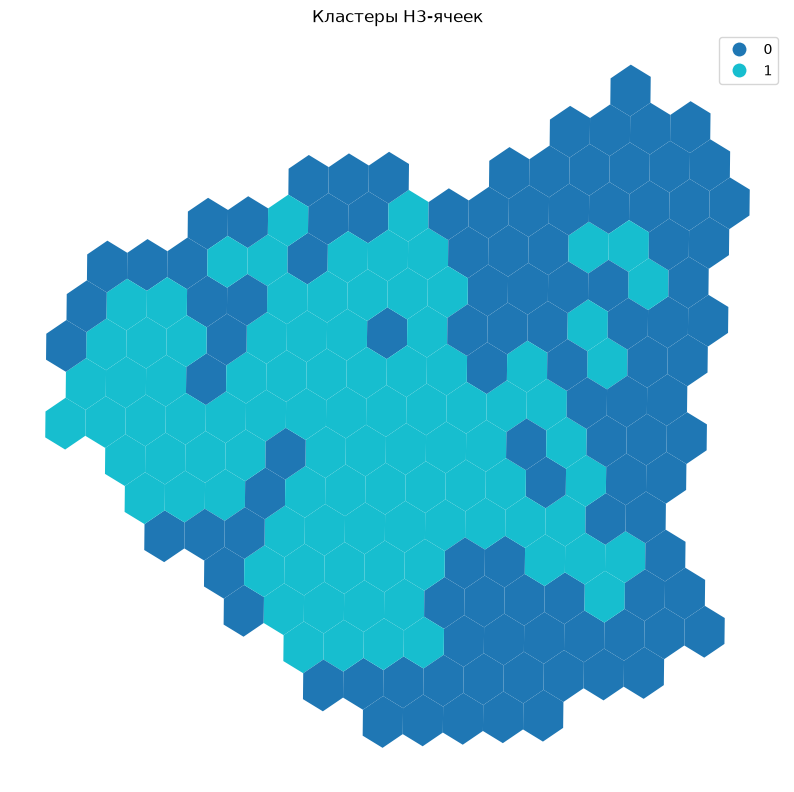

In [5]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Цель: есть ли существующая кофейня в H3-ячейке
grid["target"] = (grid["cafes"] > 0).astype(int)

print("Распределение целевой переменной:")
print(grid["target"].value_counts())
print(grid["target"].value_counts(normalize=True))

# cafes нельзя использовать как признак, поскольку из него сформирован target
model_features = [c for c in feature_cols if c != "cafes"]

X = grid[model_features].copy()
y = grid["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced"
    )
}

results = []

for name, model in models.items():
    model.fit(X_train_scaled, y_train)

    pred = model.predict(X_test_scaled)
    prob = model.predict_proba(X_test_scaled)[:, 1]

    results.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0),
        "f1": f1_score(y_test, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test, prob)
    })

results = pd.DataFrame(results).sort_values("f1", ascending=False)
display(results)

# Важность признаков Random Forest
rf = models["Random Forest"]

importance = pd.DataFrame({
    "feature": model_features,
    "importance": rf.feature_importances_
}).sort_values("importance", ascending=False)

display(importance)

plt.figure(figsize=(8, 5))
sns.barplot(data=importance, x="importance", y="feature")
plt.title("Важность признаков Random Forest")
plt.show()

# Дополнительное задание: GridSearchCV
params = {
    "n_estimators": [100, 200],
    "max_depth": [5, 10, None],
    "min_samples_leaf": [1, 3, 5]
}

search = GridSearchCV(
    RandomForestClassifier(class_weight="balanced"),
    params,
    cv=3,
    scoring="f1",
    n_jobs=1
)

search.fit(X_train_scaled, y_train)

print("Лучшие параметры Random Forest:")
print(search.best_params_)

best_model = search.best_estimator_

# Кластеризация ячеек
X_all_scaled = scaler.fit_transform(grid[model_features])

scores = []

for k in range(2, 9):
    a = KMeans(n_clusters=k, n_init=10)
    labels = a.fit_predict(X_all_scaled)
    scores.append([k, silhouette_score(X_all_scaled, labels)])

scores = pd.DataFrame(scores, columns=["k", "silhouette"])
display(scores)

best_k = int(scores.sort_values("silhouette", ascending=False).iloc[0]["k"])
print("Лучшее число кластеров:", best_k)

kmeans = KMeans(n_clusters=best_k, n_init=10)
grid["cluster"] = kmeans.fit_predict(X_all_scaled)

# Проверяем, улучшает ли кластер качество модели
X_cluster = grid[model_features + ["cluster"]]

X_train, X_test, y_train, y_test = train_test_split(
    X_cluster,
    y,
    test_size=0.25,
    stratify=y
)

scaler2 = StandardScaler()
X_train_scaled = scaler2.fit_transform(X_train)
X_test_scaled = scaler2.transform(X_test)

rf_cluster = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced"
)

rf_cluster.fit(X_train_scaled, y_train)
pred = rf_cluster.predict(X_test_scaled)
prob = rf_cluster.predict_proba(X_test_scaled)[:, 1]

print("Random Forest + cluster")
print("F1:", f1_score(y_test, pred))
print("ROC-AUC:", roc_auc_score(y_test, prob))

# Визуализация кластеров
grid.plot(
    column="cluster",
    categorical=True,
    legend=True,
    figsize=(10, 10),
    cmap="tab10"
)

plt.title("Кластеры H3-ячеек")
plt.axis("off")
plt.show()

### **Часть 4. Расчет потенциала локаций и финальные рекомендации**



1. **Разработка интегрального показателя потенциала**:
   - Самостоятельно определите веса для факторов привлекательности среды и конкуренции
   - Обоснуйте выбранные веса в контексте вашего бизнеса
   - Рассчитайте итоговый потенциал для всех ячеек сетки
   - Категоризируйте потенциал для упрощения интерпретации результатов

2. **Визуализация результатов**:
   - Создайте интерактивную карту с тепловым слоем потенциала
   - Добавьте маркеры существующих объектов вашего типа бизнеса
   - Выделите топ-10 локаций с наивысшим потенциалом
   - Подготовьте отдельную карту фокуса на лучших локациях

3. **Формирование бизнес-рекомендаций**:
   - Составьте список из 5-7 конкретных локаций для размещения новых объектов
   - Для каждой рекомендуемой локации укажите:
     * Точные координаты
     * Значение потенциала
     * Ключевые характеристики локации
     * Преимущества и возможные риски размещения в данной точке
   - Подготовьте общие рекомендации по стратегии территориального развития для выбранного бизнеса

In [6]:
from sklearn.preprocessing import MinMaxScaler
import branca.colormap as cm

# Нормализуем показатели 0..1
score_cols = [
    "shops",
    "transport",
    "education",
    "tourism",
    "parks",
    "offices",
    "restaurants",
    "pedestrian",
    "mixed_use",
    "demand_competition"
]

norm = MinMaxScaler()
scaled = pd.DataFrame(
    norm.fit_transform(grid[score_cols]),
    columns=score_cols,
    index=grid.index
)

# Близость к транспорту и паркам: меньше расстояние = выше привлекательность
grid["transport_access"] = 1 - MinMaxScaler().fit_transform(
    grid[["dist_transport"]]
).ravel()

grid["park_access"] = 1 - MinMaxScaler().fit_transform(
    grid[["dist_park"]]
).ravel()

competition = MinMaxScaler().fit_transform(
    grid[["cafes"]]
).ravel()

# Для кофеен основной упор:
# трафик/транспорт 30%, коммерческая активность 30%,
# окружение и mixed-use 25%, конкуренция -15%.
grid["potential"] = (
    0.15 * scaled["shops"] +
    0.15 * grid["transport_access"] +
    0.10 * scaled["offices"] +
    0.10 * scaled["tourism"] +
    0.10 * scaled["restaurants"] +
    0.10 * scaled["pedestrian"] +
    0.10 * scaled["mixed_use"] +
    0.10 * scaled["demand_competition"] +
    0.05 * grid["park_access"] +
    0.05 * scaled["education"] -
    0.15 * competition
)

# Нормируем итоговый индекс 0..100
grid["potential"] = MinMaxScaler(
    feature_range=(0, 100)
).fit_transform(grid[["potential"]])

grid["potential_category"] = pd.qcut(
    grid["potential"],
    q=4,
    labels=["Низкий", "Средний", "Высокий", "Очень высокий"]
)

# Для новых точек интереснее ячейки без существующих кофеен
candidates = grid[grid["cafes"] == 0].copy()
top10 = candidates.nlargest(10, "potential")

display(
    top10[
        [
            "lat",
            "lon",
            "potential",
            "shops",
            "transport",
            "offices",
            "tourism",
            "restaurants",
            "pedestrian",
            "dist_transport"
        ]
    ]
)

# Интерактивная карта через folium
center = [
    roi.geometry.iloc[0].centroid.y,
    roi.geometry.iloc[0].centroid.x
]

m = folium.Map(
    location=center,
    zoom_start=13,
    tiles="CartoDB positron"
)

color_scale = cm.linear.YlOrRd_09.scale(
    grid["potential"].min(),
    grid["potential"].max()
)

# Потенциал H3-ячеек
for _, row in grid.iterrows():
    coords = [
        [lat, lng]
        for lat, lng in h3.cell_to_boundary(row["h3"])
    ]

    folium.Polygon(
        locations=coords,
        color=color_scale(row["potential"]),
        fill=True,
        fill_color=color_scale(row["potential"]),
        fill_opacity=0.55,
        weight=0.4,
        tooltip=(
            f"Potential: {row['potential']:.1f}<br>"
            f"Shops: {row['shops']}<br>"
            f"Transport: {row['transport']}<br>"
            f"Offices: {row['offices']}<br>"
            f"Cafes: {row['cafes']}"
        )
    ).add_to(m)

color_scale.caption = "Потенциал локации"
color_scale.add_to(m)

# Существующие кофейни
for _, row in cafes_p.iterrows():
    folium.CircleMarker(
        location=[row.geometry.y, row.geometry.x],
        radius=3,
        color="blue",
        fill=True,
        fill_opacity=0.8,
        tooltip="Существующая кофейня"
    ).add_to(m)

# Топ-10 кандидатов
for i, (_, row) in enumerate(top10.iterrows(), 1):
    folium.Marker(
        location=[row["lat"], row["lon"]],
        tooltip=f"ТОП-{i}: потенциал {row['potential']:.1f}",
        icon=folium.Icon(color="red", icon="star")
    ).add_to(m)

m

# Отдельная карта лучших локаций
m_best = folium.Map(
    location=[top10["lat"].mean(), top10["lon"].mean()],
    zoom_start=14,
    tiles="CartoDB positron"
)

for i, (_, row) in enumerate(top10.iterrows(), 1):
    folium.Marker(
        [row["lat"], row["lon"]],
        popup=(
            f"<b>Локация {i}</b><br>"
            f"Потенциал: {row['potential']:.1f}<br>"
            f"Магазины: {row['shops']}<br>"
            f"Транспорт: {row['transport']}<br>"
            f"Офисы: {row['offices']}<br>"
            f"Туризм: {row['tourism']}<br>"
            f"Рестораны: {row['restaurants']}<br>"
            f"До транспорта: {row['dist_transport']:.0f} м"
        ),
        icon=folium.Icon(color="red")
    ).add_to(m_best)

m_best

# 5-7 финальных рекомендаций
recommendations = top10.head(7).copy()

recommendations["advantages"] = (
    "Хорошая коммерческая и транспортная доступность"
)

recommendations["risks"] = np.where(
    recommendations["restaurants"] > recommendations["restaurants"].median(),
    "Высокая конкуренция заведений питания",
    "Риск недостаточного локального трафика"
)

display(
    recommendations[
        [
            "lat",
            "lon",
            "potential",
            "shops",
            "transport",
            "offices",
            "tourism",
            "dist_transport",
            "advantages",
            "risks"
        ]
    ]
)

print(
    "Общая рекомендация: развивать сеть точечно в H3-ячейках с высоким "
    "потенциалом, хорошей транспортной доступностью и смешанной городской "
    "функцией, избегая зон с высокой плотностью уже существующих кофеен."
)

,lat,lon,potential,shops,transport,offices,tourism,restaurants,pedestrian,dist_transport
31,59.944399,30.391008,67.638831,17.0,2.0,3.0,4.0,3.0,0.0,89.123492
184,59.948697,30.342400,65.576508,6.0,2.0,14.0,1.0,1.0,0.0,101.435203
37,59.946868,30.382945,58.859664,11.0,4.0,4.0,0.0,1.0,0.0,20.521167
142,59.931104,30.382589,58.617646,6.0,8.0,1.0,3.0,2.0,0.0,40.166896
110,59.941613,30.382827,54.683226,12.0,7.0,1.0,1.0,3.0,0.0,140.549757
71,59.940763,30.339525,52.656218,2.0,0.0,2.0,5.0,3.0,0.0,175.178380
92,59.933573,30.374530,48.985280,13.0,2.0,4.0,0.0,2.0,0.0,133.765083
146,59.933784,30.385355,44.255262,2.0,6.0,1.0,0.0,0.0,0.0,94.191561
48,59.948804,30.347813,42.430563,1.0,4.0,5.0,0.0,0.0,0.0,31.029555
168,59.943336,30.336875,40.485960,0.0,2.0,0.0,7.0,7.0,0.0,174.904533


,lat,lon,potential,shops,transport,offices,tourism,dist_transport,advantages,risks
31,59.944399,30.391008,67.638831,17.0,2.0,3.0,4.0,89.123492,Хорошая коммерческая и транспортная доступность,Высокая конкуренция заведений питания
184,59.948697,30.342400,65.576508,6.0,2.0,14.0,1.0,101.435203,Хорошая коммерческая и транспортная доступность,Риск недостаточного локального трафика
37,59.946868,30.382945,58.859664,11.0,4.0,4.0,0.0,20.521167,Хорошая коммерческая и транспортная доступность,Риск недостаточного локального трафика
142,59.931104,30.382589,58.617646,6.0,8.0,1.0,3.0,40.166896,Хорошая коммерческая и транспортная доступность,Риск недостаточного локального трафика
110,59.941613,30.382827,54.683226,12.0,7.0,1.0,1.0,140.549757,Хорошая коммерческая и транспортная доступность,Высокая конкуренция заведений питания
71,59.940763,30.339525,52.656218,2.0,0.0,2.0,5.0,175.178380,Хорошая коммерческая и транспортная доступность,Высокая конкуренция заведений питания
92,59.933573,30.374530,48.985280,13.0,2.0,4.0,0.0,133.765083,Хорошая коммерческая и транспортная доступность,Риск недостаточного локального трафика


Общая рекомендация: развивать сеть точечно в H3-ячейках с высоким потенциалом, хорошей транспортной доступностью и смешанной городской функцией, избегая зон с высокой плотностью уже существующих кофеен.


## **Рекомендации по выполнению**


1. Начните с малой территории для тестирования кода и методологии, затем расширяйте анализ.
2. Используйте инкрементальный подход: сначала реализуйте базовый функционал, затем улучшайте его.
3. Регулярно сохраняйте промежуточные результаты работы.
4. При выборе признаков опирайтесь не только на учебный материал, но и на научные статьи по геоанализу и геомаркетингу.
5. Обращайте внимание на особенности территории и уникальные характеристики выбранного бизнеса.
6. Для оценки результатов старайтесь сопоставить их с реальным расположением успешных объектов аналогичного бизнеса.